In [1]:
pip install catboost

   ---------------------------------------- 0.0/101.8 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.8 MB 10.1 MB/s eta 0:00:10
   ---------------------------------------- 1.0/101.8 MB 10.1 MB/s eta 0:00:10
   ---------------------------------------- 1.0/101.8 MB 10.1 MB/s eta 0:00:10
   ---------------------------------------- 1.0/101.8 MB 10.1 MB/s eta 0:00:10
    --------------------------------------- 2.1/101.8 MB 1.8 MB/s eta 0:00:57
   - -------------------------------------- 3.9/101.8 MB 3.0 MB/s eta 0:00:33
   -- ------------------------------------- 6.0/101.8 MB 4.0 MB/s eta 0:00:24
   -- ------------------------------------- 7.3/101.8 MB 4.5 MB/s eta 0:00:22
   --- ------------------------------------ 8.4/101.8 MB 4.4 MB/s eta 0:00:22
   --- ------------------------------------ 8.9/101.8 MB 4.1 MB/s eta 0:00:23
   ---- ----------------------------------- 10.5/101.8 MB 4.6 MB/s eta 0:00:20
   ---- ----------------------------------- 10.5/101.8 MB 4.6 MB/s

In [2]:
pip install lightgbm


   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------- ----------- 1.0/1.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 5.4 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import optuna
import lightgbm as lgb
import catboost as cb

[I 2025-03-16 16:51:38,247] A new study created in memory with name: no-name-ee6cbdce-f778-4f36-955c-3dcf505d30f6
[I 2025-03-16 16:51:38,611] Trial 0 finished with value: 0.837 and parameters: {'learning_rate': 0.032859903454529785, 'num_leaves': 78, 'max_depth': 4, 'min_data_in_leaf': 35, 'lambda_l1': 0.16545053224963097, 'lambda_l2': 0.00018546863791589545}. Best is trial 0 with value: 0.837.


[LightGBM] [Warning] min_data_in_leaf is set=35, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=35
[LightGBM] [Warning] lambda_l1 is set=0.16545053224963097, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.16545053224963097
[LightGBM] [Warning] lambda_l2 is set=0.00018546863791589545, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.00018546863791589545
[LightGBM] [Warning] min_data_in_leaf is set=35, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=35
[LightGBM] [Warning] lambda_l1 is set=0.16545053224963097, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.16545053224963097
[LightGBM] [Warning] lambda_l2 is set=0.00018546863791589545, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.00018546863791589545
[LightGBM] [Info] Number of positive: 4012, number of negative: 3988
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001692 seconds.
You can set `force_row_wise=t

[I 2025-03-16 16:51:38,788] Trial 1 finished with value: 0.9205 and parameters: {'learning_rate': 0.2273375254132184, 'num_leaves': 187, 'max_depth': 4, 'min_data_in_leaf': 34, 'lambda_l1': 1.0592613581771149e-07, 'lambda_l2': 0.00022355026211543004}. Best is trial 1 with value: 0.9205.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2025-03-16 16:51:39,158] Trial 2 finished with value: 0.935 and parameters: {'learning_rate': 0.10284064814440405, 'num_leaves': 128, 'max_depth': 14, 'min_data_in_leaf': 99, 'lambda_l1': 0.01676528678920955, 'lambda_l2': 0.00013816391824366748}. Best is trial 2 with value: 0.935.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] min_data_in_leaf is set=99, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=99
[LightGBM] [Warning] lambda_l1 is set=0.01676528678920955, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.01676528678920955
[LightGBM] [Warning] lambda_l2 is set=0.00013816391824366748, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.00013816391824366748
[LightGBM] [Warning] min_data_in_leaf is set=79, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=79
[LightGBM] [Warning] lambda_l1 is set=0.0002227557397614828, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.0002227557397614828
[LightGBM] [Warning] lambda_l2 is set=2.637019751596637e-07, reg_lambda=0.0 will be ignored. Current value: lambda_l2=2.637019751596637e-07
[LightGBM] [Warning] min_data_in_leaf is set=79, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=79
[Li

... (28 outputs left out)

[I 2025-03-16 16:51:45,926] Trial 18 finished with value: 0.9325 and parameters: {'learning_rate': 0.07297916225677599, 'num_leaves': 174, 'max_depth': 15, 'min_data_in_leaf': 47, 'lambda_l1': 0.0008957770082506261, 'lambda_l2': 0.6885590515809602}. Best is trial 14 with value: 0.9725.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2025-03-16 16:51:46,576] Trial 19 finished with value: 0.972 and parameters: {'learning_rate': 0.2121795321525874, 'num_leaves': 124, 'max_depth': 13, 'min_data_in_leaf': 22, 'lambda_l1': 0.024805028444736036, 'lambda_l2': 0.0021360782446930163}. Best is trial 14 with value: 0.9725.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] min_data_in_leaf is set=22, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=22
[LightGBM] [Warning] lambda_l1 is set=0.024805028444736036, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.024805028444736036
[LightGBM] [Warning] lambda_l2 is set=0.0021360782446930163, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.0021360782446930163
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Warning] lambda_l1 is set=0.002525308734203759, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.002525308734203759
[LightGBM] [Warning] lambda_l2 is set=0.13

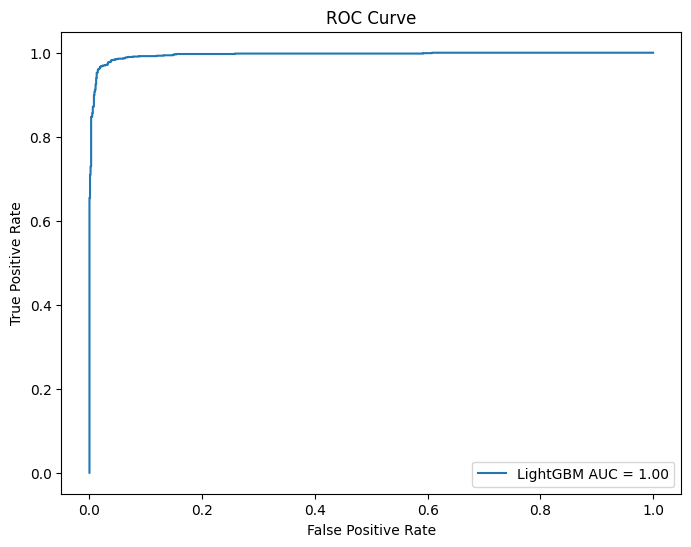

[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Warning] lambda_l1 is set=0.002525308734203759, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.002525308734203759
[LightGBM] [Warning] lambda_l2 is set=0.13470092542672654, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.13470092542672654


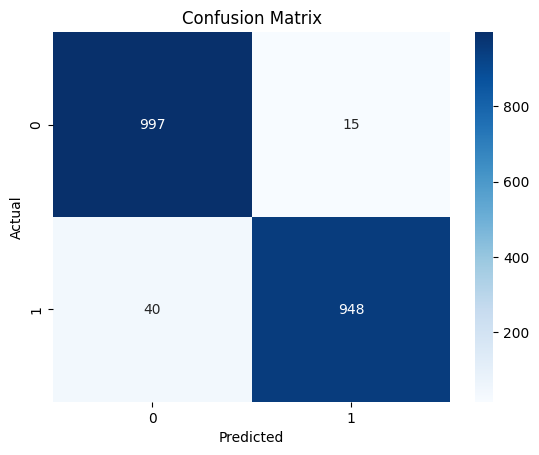

In [5]:
# Load dataset
df = pd.read_csv(r"D:\SDP\Phishing\URL\5.urldata.csv")  # Change filename accordingly

# Feature selection and preprocessing
X = df.drop(columns=['Label'])  # Assuming 'Label' is the target column
y = df['Label']

# Handle categorical variables
label_encoders = {}
for col in X.select_dtypes(include=['object']).columns:
    label_encoders[col] = LabelEncoder()
    X[col] = label_encoders[col].fit_transform(X[col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Hyperparameter tuning for LightGBM
def objective(trial):
    param = {
        'objective': 'binary',
        'metric': 'binary_logloss',
        'boosting_type': 'gbdt',
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 10, 100),
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-8, 10.0, log=True),
    }
    model = lgb.LGBMClassifier(**param)
    model.fit(X_train, y_train)
    return accuracy_score(y_test, model.predict(X_test))

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

# Train LightGBM with best parameters
lgb_best = lgb.LGBMClassifier(**study.best_params)
lgb_best.fit(X_train, y_train)

# Train CatBoost
gb = cb.CatBoostClassifier(iterations=200, depth=10, learning_rate=0.1, verbose=0)
gb.fit(X_train, y_train)

# Neural Network Model
class PhishingNN(nn.Module):
    def __init__(self, input_dim):
        super(PhishingNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.fc3 = nn.Linear(64, 1)
        self.dropout = nn.Dropout(0.3)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        x = torch.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)
        x = torch.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = self.sigmoid(self.fc3(x))
        return x

# Prepare PyTorch dataset
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train_torch = torch.tensor(X_train.values, dtype=torch.float32).to(device)
y_train_torch = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1).to(device)
X_test_torch = torch.tensor(X_test.values, dtype=torch.float32).to(device)
y_test_torch = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1).to(device)
train_dataset = TensorDataset(X_train_torch, y_train_torch)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Train Neural Network
model = PhishingNN(X_train.shape[1]).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):  # Train for 20 epochs
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

# Save the trained model
torch.save(model.state_dict(), "D:/SDP/Phishing/URL/model/phishing_url_model.pth")

# Evaluation
models = {"LightGBM": lgb_best, "CatBoost": gb}
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"{name} - Accuracy: {accuracy_score(y_test, y_pred)}")
    print(f"{name} - F1 Score: {f1_score(y_test, y_pred)}")
    print(f"{name} - Recall: {recall_score(y_test, y_pred)}")
    print(f"{name} - Precision: {precision_score(y_test, y_pred)}")

# ROC Curve
plt.figure(figsize=(8, 6))
y_probs = lgb_best.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'LightGBM AUC = {roc_auc:.2f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, lgb_best.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [2]:
pip install category_encoders


   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ------- -------------------------------- 2.1/11.1 MB 9.8 MB/s eta 0:00:01
   ------------- -------------------------- 3.7/11.1 MB 8.7 MB/s eta 0:00:01
   ------------------- -------------------- 5.5/11.1 MB 8.8 MB/s eta 0:00:01
   -------------------------- ------------- 7.3/11.1 MB 8.5 MB/s eta 0:00:01
   -------------------------------- ------- 8.9/11.1 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------  11.0/11.1 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------- 11.1/11.1 MB 8.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.8 MB 9.1 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.8 MB 9.7 MB/s eta 0:00:01
   ------------------------- -------------- 6.3/9.8 MB 9.9 MB/s eta 0:00:01
   --------------------------------- ------ 8.1/9.8 MB 9.5 MB/s eta 0:00:01
   ------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastai 2.7.12 requires torch<2.1,>=1.7, but you have torch 2.5.1 which is incompatible.

[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: C:\Users\Chetan Sri Reddy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [16]:
pip install tldextract

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 25.1
[notice] To update, run: C:\Users\Chetan Sri Reddy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Using Multi Modal

In [15]:
# Import required libraries
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from category_encoders import TargetEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from pytorch_tabnet.tab_model import TabNetClassifier
import optuna

[I 2025-04-30 00:41:39,262] A new study created in memory with name: no-name-ecb812ce-e46d-454f-9537-2b25d785771a
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 1.58386 | val_0_auc: 0.64255 |  0:00:02s
epoch 1  | loss: 0.681   | val_0_auc: 0.736   |  0:00:05s
epoch 2  | loss: 0.45869 | val_0_auc: 0.78868 |  0:00:07s
epoch 3  | loss: 0.36786 | val_0_auc: 0.85474 |  0:00:10s
epoch 4  | loss: 0.26772 | val_0_auc: 0.94189 |  0:00:12s
epoch 5  | loss: 0.19378 | val_0_auc: 0.94691 |  0:00:14s
epoch 6  | loss: 0.18003 | val_0_auc: 0.96612 |  0:00:17s
epoch 7  | loss: 0.1182  | val_0_auc: 0.97407 |  0:00:19s
epoch 8  | loss: 0.11126 | val_0_auc: 0.98019 |  0:00:21s
epoch 9  | loss: 0.09195 | val_0_auc: 0.98469 |  0:00:24s
epoch 10 | loss: 0.06447 | val_0_auc: 0.97483 |  0:00:26s
epoch 11 | loss: 0.04968 | val_0_auc: 0.98788 |  0:00:28s
epoch 12 | loss: 0.04043 | val_0_auc: 0.98613 |  0:00:31s
epoch 13 | loss: 0.0289  | val_0_auc: 0.98694 |  0:00:33s
epoch 14 | loss: 0.02349 | val_0_auc: 0.98331 |  0:00:36s

Early stopping occurred at epoch 14 with best_epoch = 11 and best_val_0_auc = 0.98788


C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-30 00:42:16,862] Trial 0 finished with value: 0.9195 and parameters: {'n_d': 48, 'n_a': 11, 'n_steps': 8, 'gamma': 1.5874469488222147, 'lambda_sparse': 0.0007280086219736467, 'lr': 0.005042396525392353}. Best is trial 0 with value: 0.9195.
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 1.14909 | val_0_auc: 0.81743 |  0:00:02s
epoch 1  | loss: 0.30572 | val_0_auc: 0.93265 |  0:00:04s
epoch 2  | loss: 0.10518 | val_0_auc: 0.97721 |  0:00:06s
epoch 3  | loss: 0.04189 | val_0_auc: 0.99162 |  0:00:09s
epoch 4  | loss: 0.01882 | val_0_auc: 0.99516 |  0:00:11s
epoch 5  | loss: 0.01104 | val_0_auc: 0.99675 |  0:00:13s
epoch 6  | loss: 0.00749 | val_0_auc: 0.99875 |  0:00:15s
epoch 7  | loss: 0.00517 | val_0_auc: 0.99888 |  0:00:17s
epoch 8  | loss: 0.00384 | val_0_auc: 0.99909 |  0:00:20s
epoch 9  | loss: 0.00506 | val_0_auc: 0.9992  |  0:00:22s
epoch 10 | loss: 0.00349 | val_0_auc: 0.99893 |  0:00:24s
epoch 11 | loss: 0.00571 | val_0_auc: 0.99908 |  0:00:26s
epoch 12 | loss: 0.00332 | val_0_auc: 0.99926 |  0:00:28s
epoch 13 | loss: 0.00172 | val_0_auc: 0.99925 |  0:00:30s
epoch 14 | loss: 0.00312 | val_0_auc: 0.99922 |  0:00:32s
epoch 15 | loss: 0.00115 | val_0_auc: 0.99923 |  0:00:35s

Early stopping occurred at epoch 15 with best_epoch = 12 and best_val_0

C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-30 00:42:53,085] Trial 1 finished with value: 0.881 and parameters: {'n_d': 20, 'n_a': 51, 'n_steps': 6, 'gamma': 1.091029121099739, 'lambda_sparse': 0.00033964912942313906, 'lr': 0.008388258523769244}. Best is trial 0 with value: 0.9195.
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.60978 | val_0_auc: 0.84994 |  0:00:01s
epoch 1  | loss: 0.16882 | val_0_auc: 0.9545  |  0:00:03s
epoch 2  | loss: 0.09353 | val_0_auc: 0.97446 |  0:00:04s
epoch 3  | loss: 0.05008 | val_0_auc: 0.99036 |  0:00:06s
epoch 4  | loss: 0.02786 | val_0_auc: 0.99337 |  0:00:07s
epoch 5  | loss: 0.0173  | val_0_auc: 0.9956  |  0:00:09s
epoch 6  | loss: 0.01144 | val_0_auc: 0.99727 |  0:00:10s
epoch 7  | loss: 0.01233 | val_0_auc: 0.99811 |  0:00:12s
epoch 8  | loss: 0.00776 | val_0_auc: 0.99875 |  0:00:14s
epoch 9  | loss: 0.00667 | val_0_auc: 0.99885 |  0:00:16s
epoch 10 | loss: 0.0054  | val_0_auc: 0.99904 |  0:00:17s
epoch 11 | loss: 0.00498 | val_0_auc: 0.99907 |  0:00:19s
epoch 12 | loss: 0.00385 | val_0_auc: 0.99889 |  0:00:20s
epoch 13 | loss: 0.00368 | val_0_auc: 0.99867 |  0:00:22s
epoch 14 | loss: 0.00416 | val_0_auc: 0.99889 |  0:00:23s

Early stopping occurred at epoch 14 with best_epoch = 11 and best_val_0_auc = 0.99907


C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
[I 2025-04-30 00:43:17,316] Trial 2 finished with value: 0.891 and parameters: {'n_d': 62, 'n_a': 13, 'n_steps': 4, 'gamma': 1.0239242763144878, 'lambda_sparse': 0.00023236233567761484, 'lr': 0.005125079133793687}. Best is trial 0 with value: 0.9195.
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 1.58386 | val_0_auc: 0.64255 |  0:00:02s
epoch 1  | loss: 0.681   | val_0_auc: 0.736   |  0:00:04s
epoch 2  | loss: 0.45869 | val_0_auc: 0.78868 |  0:00:07s
epoch 3  | loss: 0.36786 | val_0_auc: 0.85474 |  0:00:09s
epoch 4  | loss: 0.26772 | val_0_auc: 0.94189 |  0:00:11s
epoch 5  | loss: 0.19378 | val_0_auc: 0.94691 |  0:00:14s
epoch 6  | loss: 0.18003 | val_0_auc: 0.96612 |  0:00:16s
epoch 7  | loss: 0.1182  | val_0_auc: 0.97407 |  0:00:18s
epoch 8  | loss: 0.11126 | val_0_auc: 0.98019 |  0:00:21s
epoch 9  | loss: 0.09195 | val_0_auc: 0.98469 |  0:00:23s
epoch 10 | loss: 0.06447 | val_0_auc: 0.97483 |  0:00:26s
epoch 11 | loss: 0.04968 | val_0_auc: 0.98788 |  0:00:28s
epoch 12 | loss: 0.04043 | val_0_auc: 0.98613 |  0:00:30s
epoch 13 | loss: 0.0289  | val_0_auc: 0.98694 |  0:00:33s
epoch 14 | loss: 0.02349 | val_0_auc: 0.98331 |  0:00:35s

Early stopping occurred at epoch 14 with best_epoch = 11 and best_val_0_auc = 0.98788


C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")
C:\Users\Chetan Sri Reddy\AppData\Local\Temp\ipykernel_21584\3151843555.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default va

Accuracy: 0.9195
F1 Score: 0.9131
Recall: 0.8563
Precision: 0.9780


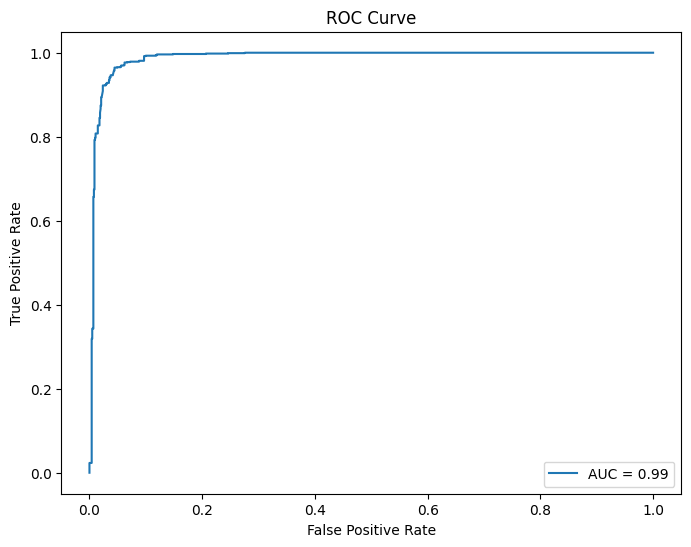

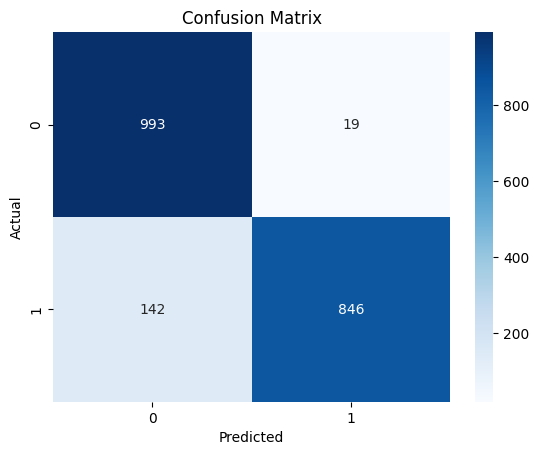

In [19]:
# Load dataset
df = pd.read_csv(r"D:\SDP\Phishing\URL\5.urldata.csv")

# Separate features and target
X = df.drop(columns=['Label'])
y = df['Label']

# Preprocessing
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', TargetEncoder(), categorical_cols)
    ]
)

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit and transform
preprocessor.fit(X_train_raw, y_train)
X_train = preprocessor.transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# Convert to numpy arrays
X_train = np.array(X_train)
X_test = np.array(X_test)

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Optuna objective function
def objective(trial):
    params = {
        "n_d": trial.suggest_int("n_d", 8, 64),
        "n_a": trial.suggest_int("n_a", 8, 64),
        "n_steps": trial.suggest_int("n_steps", 3, 10),
        "gamma": trial.suggest_float("gamma", 1.0, 2.0),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3),
        "optimizer_fn": torch.optim.Adam,
        "optimizer_params": dict(lr=trial.suggest_float("lr", 1e-4, 1e-2)),
        "mask_type": "entmax",
        "device_name": device.type
    }

    model = TabNetClassifier(**params)
    model.fit(
        X_train,
        y_train.values,
        eval_set=[(X_test, y_test.values)],
        patience=3
    )
    preds = model.predict(X_test)
    return accuracy_score(y_test, preds)

# Run Optuna optimization
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=3)

# Extract best parameters
best_params = study.best_params.copy()
lr = best_params.pop("lr")

# Train final model
final_model = TabNetClassifier(
    **best_params,
    optimizer_fn=torch.optim.Adam,
    optimizer_params={"lr": lr},
    mask_type="entmax",
    device_name=device.type
)

final_model.fit(
    X_train,
    y_train.values,
    eval_set=[(X_test, y_test.values)],
    patience=3
)

# Save model in PyTorch `.pth` format (state_dict only)
# Saving the model
torch.save(final_model, "D:/SDP/Phishing/URL/model/phishing_tabnet_full.pth")

# --------- Optional: Load model later ---------
# Re-initialize the model with same parameters
loaded_model = TabNetClassifier(
    **best_params,
    optimizer_fn=torch.optim.Adam,
    optimizer_params={"lr": lr},
    mask_type="entmax",
    device_name=device.type
)
# Load saved weights
loaded_model = torch.load("D:/SDP/Phishing/URL/model/phishing_tabnet_full.pth")

# --------- Evaluation ---------
y_pred = final_model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")

# ROC Curve
y_probs = final_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


# Validation of MultiModal

In [3]:
import numpy as np
import pandas as pd
import torch
from pytorch_tabnet.tab_model import TabNetClassifier
import joblib
import re
from urllib.parse import urlparse

# ----------- Custom Feature Extraction from URL -------------
def extract_features(url):
    parsed = urlparse(url)
    features = {
        "url_length": len(url),
        "hostname_length": len(parsed.netloc),
        "path_length": len(parsed.path),
        "count_dots": url.count('.'),
        "count_slashes": url.count('/'),
        "has_https": int(parsed.scheme == 'https'),
        "count_at": url.count('@'),
        "count_hyphen": url.count('-'),
        "count_equal": url.count('='),
        "count_question": url.count('?'),
        "count_percent": url.count('%'),
        "count_digits": sum(c.isdigit() for c in url),
        "count_letters": sum(c.isalpha() for c in url),
        "is_ip": int(bool(re.match(r'^\d{1,3}(\.\d{1,3}){3}', parsed.netloc))),
        "count_underscore": url.count('_'),
        "count_ampersand": url.count('&'),
        "count_colon": url.count(':')
    }
    return np.array(list(features.values()), dtype=np.float32).reshape(1, -1)



# ----------- Load Pre-trained TabNet Model -------------------
model = TabNetClassifier()
model.load_model("D:/SDP/Phishing/URL/model/phishing_tabnet.pth.zip")  # Make sure this file exists in the same directory

# Set model to evaluation mode
model.network.eval()

# ----------- Prediction Function -----------------------------
def predict_url(url):
    features = extract_features(url)
    input_tensor = torch.from_numpy(features)
    try:
        # Ensure model is on CPU if no CUDA
        prediction = model.predict(input_tensor)
        label = "Phishing" if prediction[0] == 1 else "Legitimate"
        print(f"✅ Prediction for {url}: {label}")
    except Exception as e:
        print("❌ Prediction failed:", e)

# ----------- Test the Function -------------------------------
if __name__ == "__main__":
    print("🔐 Phishing URL Detector (TabNet-based)")
    print("Enter a URL to check (or type 'exit' to quit):")
    
    while True:
        user_input = input("🔎 URL: ").strip()
        if user_input.lower() == 'exit':
            print("👋 Exiting the URL checker.")
            break
        if not user_input:
            print("⚠️ Please enter a valid URL or 'exit'.")
            continue
        predict_url(user_input)

🔐 Phishing URL Detector (TabNet-based)
Enter a URL to check (or type 'exit' to quit):


🔎 URL:  http://shopsy.com


✅ Prediction for http://shopsy.com: Phishing


🔎 URL:  google.com


✅ Prediction for google.com: Legitimate


🔎 URL:  exit


👋 Exiting the URL checker.
